In [1]:
from src.gradient import SLMphaseRetrievalCG,build_input,build_pbb_target,SLMphaseRetrievalCG3D
from src.utils import phase_pbb_10,get_bb_optimal_a
import torch
import matplotlib.pyplot as plt
import numpy as np
%load_ext autoreload
%autoreload 2

/Users/apple/anaconda3/envs/slm/lib/python3.13/site-packages/slmsuite/holography/algorithms/_header.py:30: UserWarning: cupy is not installed; using numpy. Install cupy for faster GPU-based holography.
  warnings.warn(


In [2]:
get_bb_optimal_a(2.53538014e+02,1980)

np.float64(211.0842426594649)

In [3]:
pad_factor = 4
A_input = build_input()
A_target = build_pbb_target(pad_factor=pad_factor,n=6)

# J6_phase = torch.tensor(bottle_beam_phase())

m = SLMphaseRetrievalCG(A_in = A_input,A_t = A_target,pad_factor=pad_factor)

/Users/apple/Desktop/holography/src/gradient.py:128: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.A_in = self.pad(torch.tensor(A_in / FeedbackHologram._norm(A_in), dtype=torch.float32))
/Users/apple/Desktop/holography/src/gradient.py:134: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.A_t = torch.tensor(A_t / FeedbackHologram._norm(A_t), dtype=torch.float32)


In [4]:
def bottle_beam_phase():
    ro = 100
    return np.array([[np.pi if ((i-512)**2 + (j-640)**2) <= ro**2 else 0 for j in range(1280)] for i in range(1024)])


def phase_pbb_2n_superposed(order=2, H=1024, W=1280, center_y=None, center_x=None):
    "superpose n*theta and - n*theta"
    if center_y is None:
        center_y = H // 2
    if center_x is None:
        center_x = W // 2

    # Create coordinate grid
    y = torch.arange(H).view(-1, 1).expand(H, W)
    x = torch.arange(W).view(1, -1).expand(H, W)
    theta = torch.atan2(y - center_y, x - center_x)
    r =(y - center_y) ** 2 + (x - center_x) ** 2
    # Base phase pattern
    phase = order * theta   # +5θ
    rand_mask = torch.rand(H, W) > 1.7/2
    phase[rand_mask == False] *= -1
    return phase  # Shape: (H, W)



def phase_pbb_n_bb_superposed(order=2, H=1024, W=1280, center_y=None, center_x=None):
    if center_y is None:
        center_y = H // 2
    if center_x is None:
        center_x = W // 2

    # Create coordinate grid
    y = torch.arange(H).view(-1, 1).expand(H, W)
    x = torch.arange(W).view(1, -1).expand(H, W)
    theta = torch.atan2(y - center_y, x - center_x)
    r =(y - center_y) ** 2 + (x - center_x) ** 2
    # Base phase pattern
    phase = order * theta + 1e-2*(r**0.5)  # +5θ
    # rand_mask = torch.rand(H, W) > 0.5
    # phase[rand_mask == False] *= -1

    r_mask2 = r<200**2
    phase2 = torch.zeros_like(phase)
    phase2[r_mask2 == True] += torch.pi

    # Create 50% random mask: True => use +5θ, False => use -5θ
    # rand_mask = torch.rand(H, W) > 1.7/2
    r_mask3 = torch.rand(H, W) > 0.5
    phase[r_mask3 == True] = phase2[r_mask3 == True]
    # phase[rand_mask == False] = phase2[rand_mask == False]  # Flip sign where mask is False


    return phase  # Shape: (H, W)





def phase_pbb_2n_bb_superposed(order=2, H=1024, W=1280, center_y=None, center_x=None):
    "superpose n*theta and - n*theta with a bottle beam "
    if center_y is None:
        center_y = H // 2
    if center_x is None:
        center_x = W // 2

    # Create coordinate grid
    y = torch.arange(H).view(-1, 1).expand(H, W)
    x = torch.arange(W).view(1, -1).expand(H, W)
    theta = torch.atan2(y - center_y, x - center_x)
    r =(y - center_y) ** 2 + (x - center_x) ** 2
    # Base phase pattern
    phase = order * theta   # +5θ
    rand_mask = torch.rand(H, W) > 0.5
    phase[rand_mask == False] *= -1

    r_mask2 = r<200**2
    phase2 = torch.zeros_like(phase)
    phase2[r_mask2 == True] += torch.pi

    r_mask3 = torch.rand(H, W) > 0.5
    phase[r_mask3 == True] = phase2[r_mask3 == True]
    
    return phase  # Shape: (H, W)

In [23]:
pbb_2n_superposed = torch.tensor(phase_pbb_2n_superposed(order=3, H=1024, W=1280))
pbb_2n_bb_superposed = torch.tensor(phase_pbb_2n_bb_superposed(order=3, H=1024, W=1280))
pbb_n_bb_superposed = torch.tensor(phase_pbb_n_bb_superposed(order=6, H=1024, W=1280))

/var/folders/py/_lrzt4sd23jgrnhmp_01ng8h0000gn/T/ipykernel_63971/2906021587.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  pbb_2n_superposed = torch.tensor(phase_pbb_2n_superposed(order=3, H=1024, W=1280))
/var/folders/py/_lrzt4sd23jgrnhmp_01ng8h0000gn/T/ipykernel_63971/2906021587.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  pbb_2n_bb_superposed = torch.tensor(phase_pbb_2n_bb_superposed(order=3, H=1024, W=1280))
/var/folders/py/_lrzt4sd23jgrnhmp_01ng8h0000gn/T/ipykernel_63971/2906021587.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourc

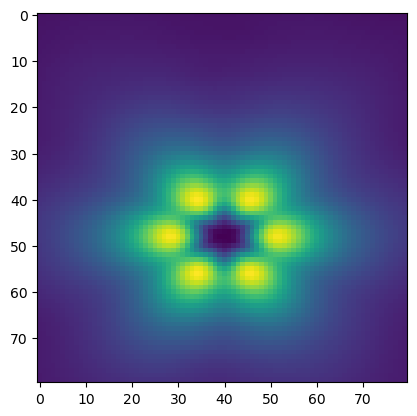

In [16]:
plt.imshow(m.forward_propagate(m.pad(tensor=A_input)*m.pad(tensor=torch.exp(1j*pbb_2n_superposed))).abs()[500*pad_factor:520*pad_factor,630*pad_factor:650*pad_factor])

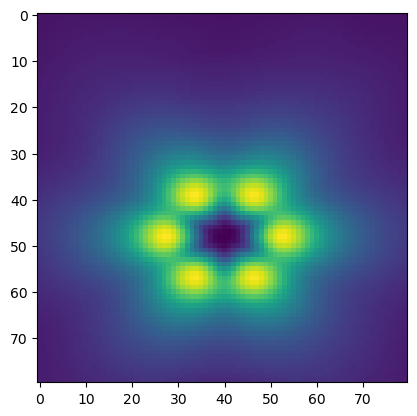

In [17]:
plt.imshow(m.forward_propagate(m.pad(tensor=A_input)*m.pad(tensor=torch.exp(1j*pbb_2n_superposed)),z = 0.000001*10).abs()[500*pad_factor:520*pad_factor,630*pad_factor:650*pad_factor])

In [10]:
import numpy as np
import plotly.graph_objects as go

def plot_3d_surface(array_2d, title="3D Surface Plot"):
    """
    Plots a 2D NumPy array as a 3D surface using Plotly.

    Parameters:
    - array_2d: 2D numpy array
    - title: Optional title for the plot
    """
    x = np.arange(array_2d.shape[1])
    y = np.arange(array_2d.shape[0])
    x_grid, y_grid = np.meshgrid(x, y)

    fig = go.Figure(data=[go.Surface(z=array_2d, x=x_grid, y=y_grid)])
    fig.update_layout(title=title, scene=dict(
        xaxis_title='X',
        yaxis_title='Y',
        zaxis_title='Z'),
        autosize=True,
        margin=dict(l=0, r=0, b=0, t=30)
    )
    fig.show()

In [19]:
# plot_3d_surface(array_2d=m.forward_propagate(m.pad(tensor=A_input)*m.pad(tensor=torch.exp(1j*pbb_2n_superposed))).abs()[500*pad_factor:520*pad_factor,630*pad_factor:650*pad_factor])

In [24]:
m3d = SLMphaseRetrievalCG3D(A_in = A_input,A_t = None,pad_factor=pad_factor)

In [20]:
targ = m3d.build_target_from_phase(pbb_2n_superposed)

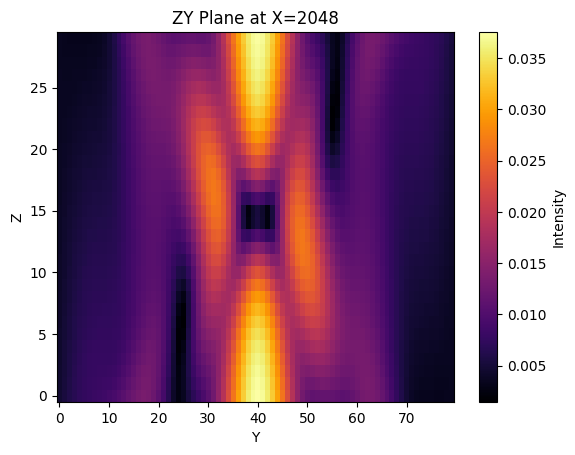

In [ ]:
x_index = 512*m3d.pad_factor  # middle x-slice
zy_slice = m3d.A_t[:,x_index, 630*m3d.pad_factor:650*m3d.pad_factor]

plt.imshow(zy_slice, aspect='auto', cmap='inferno', origin='lower')
plt.colorbar(label='Intensity')
plt.xlabel('Y')
plt.ylabel('Z')
plt.title(f'ZY Plane at X={x_index}')
plt.show()

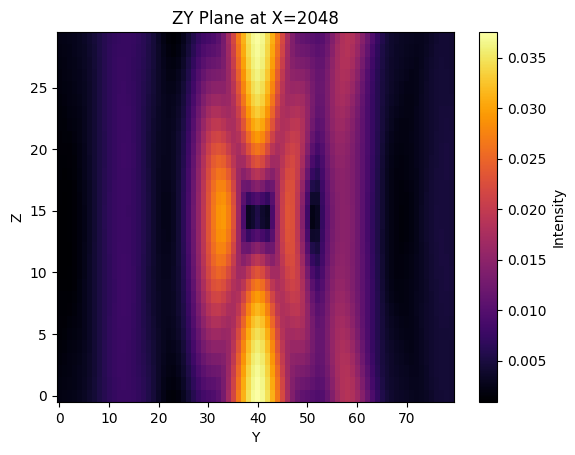

In [ ]:
y_index = 640*m3d.pad_factor  # middle x-slice
zy_slice = m3d.A_t[:, 502*m3d.pad_factor:522*m3d.pad_factor,y_index]

plt.imshow(zy_slice, aspect='auto', cmap='inferno', origin='lower')
plt.colorbar(label='Intensity')
plt.xlabel('Y')
plt.ylabel('Z')
plt.title(f'ZY Plane at X={x_index}')
plt.show()

In [ ]:
import matplotlib.pyplot as plt

def plot_cropped_sections(A_t, pad_factor):
    # compute indices & crops
    nz, ny, nx = A_t.shape
    z_center = (nz ) // 2

    z0    = z_center
    x_idx = 512 * pad_factor
    y_idx = 640 * pad_factor

    xy = A_t[z0,
             500 * pad_factor : 520 * pad_factor,
             630 * pad_factor : 650 * pad_factor]

    yz = A_t[:,
             x_idx,
             630 * pad_factor : 650 * pad_factor]

    xz = A_t[:, 
             502 * pad_factor : 522 * pad_factor,
             y_idx]

    # plot all three in one row
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # XY @ Z=0
    im0 = axes[0].imshow(xy, aspect='auto', origin='lower', cmap='inferno')
    axes[0].set_title(f'XY @ Z={z0}')
    axes[0].set_xlabel('X (cropped)')
    axes[0].set_ylabel('Y (cropped)')
    fig.colorbar(im0, ax=axes[0], label='Intensity')

    # YZ @ X=middle
    im1 = axes[1].imshow(yz, aspect='auto', origin='lower', cmap='inferno')
    axes[1].set_title(f'YZ @ X={x_idx}')
    axes[1].set_xlabel('Z')
    axes[1].set_ylabel('Y')
    fig.colorbar(im1, ax=axes[1], label='Intensity')

    # XZ @ Y=middle
    im2 = axes[2].imshow(xz, aspect='auto', origin='lower', cmap='inferno')
    axes[2].set_title(f'XZ @ Y={y_idx}')
    axes[2].set_xlabel('X (cropped)')
    axes[2].set_ylabel('Z')
    fig.colorbar(im2, ax=axes[2], label='Intensity')

    plt.tight_layout()
    plt.show()


**Phase**

The phase is the superposition of $3\theta$ and $-3\theta$, e.g.:

$$
\text{Phase} =
\begin{cases}
3\theta, & \text{if }\text{rand}<0.15,\\
-3\theta, & \text{otherwise}.
\end{cases}
$$

---

**Far‑field Amplitude**

The far‑field field is the convolution of the Bessel‑cosine pattern with the optical‑tweezer point‑spread function $(E_{\rm tweezer}(r,\theta)$):

$$
E_{\rm ff}(r,\theta)
= \Bigl[J_{n}(r)\,\bigl(a\cos(2n\theta) + b\bigr)\Bigr]
\;\ast\;
E_{\rm tweezer}(r,\theta)
$$

$$
E(0,z)
=
\int_{0}^{\infty}
E_{\rm tweezer}(r,\theta)\,
\exp\!\Bigl(-i\,\frac{k\,r^{2}}{2f}\Bigr)\,
J_{n}\!(0)\;r\,dr,
$$








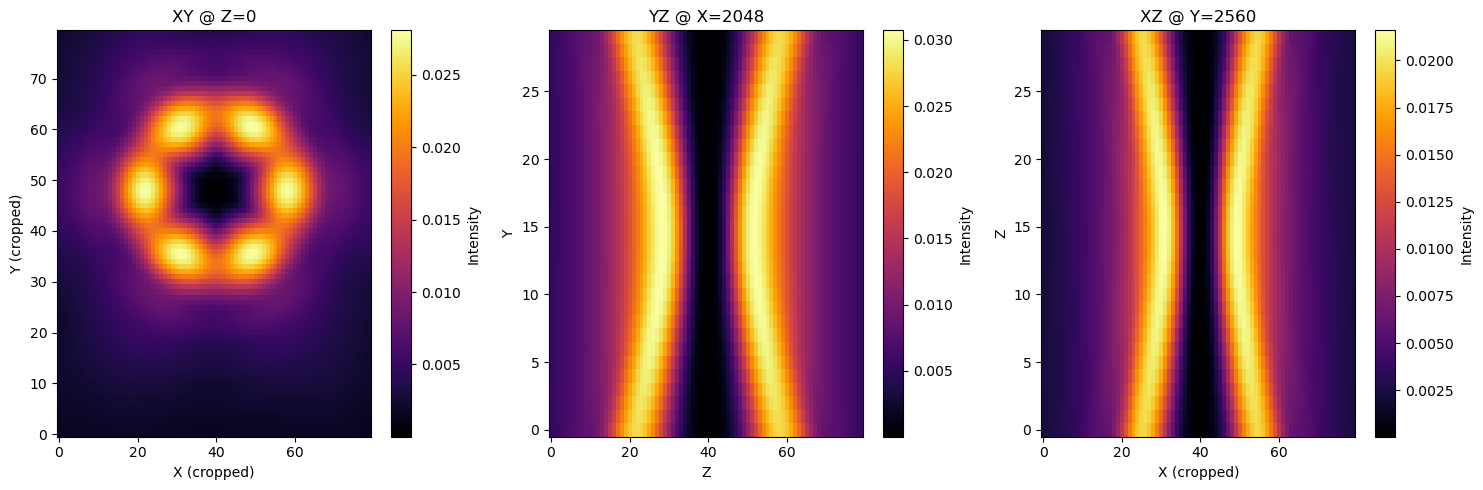

In [ ]:
targ = m3d.build_target_from_phase(pbb_2n_superposed)
plot_cropped_sections(m3d.A_t, m3d.pad_factor)


The angular expansion of phase mask is 
$$
e^{i\Phi(r,\theta)}
\;=\;
\sum_{n=-\infty}^{\infty}
\varphi_{n}(r)\;e^{i\,n\,\theta},
$$

$$
E(k,\theta_k)
=\int_{0}^{\infty}\!\!\int_{0}^{2\pi}
e^{i\Phi(r,\theta)}\,e^{-i k r\cos(\theta-\theta_k)}\,r\,d\theta\,dr
=
\sum_{n=-\infty}^{\infty}
\Bigl[i^{\,n} \!\!\int_{0}^{\infty}\varphi_{n}(r)\,J_{n}(k\,r)\,r\,dr\Bigr]\;e^{i n\,\theta_k}.
$$

$$
E(k=0, z)
=
\sum_{n=-\infty}^{\infty}
i^n 
\!\int_{0}^{\infty}
\varphi_{n}(r)\,J_{n}(0)\,
\exp\!\Bigl(-i\frac{k\,r^{2}}{2f}\Bigr)\,r\,dr
\;=\;
\int_{0}^{\infty}
\varphi_{0}(r)\,
\exp\!\Bigl(-i\frac{k\,r^{2}}{2f}\Bigr)\,r\,dr.
$$

All terms other than n=0 gives null axial profile $E_n[0,z] = 0$ for $n!=0$

**Phase**

We choose between a bottle‑beam phase and a ±3θ phase by two independent draws, rand₁ and rand₂:

$$
\phi(r,\theta) =
\begin{cases}
\phi_{\rm bottle}(r,\theta), 
   & \text{if }\; \mathrm{rand}_1 < 0.5,\\[6pt]
\begin{cases}
3\theta,  & \text{if }\; \mathrm{rand}_2 < 0.5,\\[3pt]
-3\theta, & \text{otherwise},
\end{cases}
   & \text{otherwise}.
\end{cases}
$$

---

**Far‑field Amplitude**

Now we superpose the usual $J_{n+1}(r)\cos(2n\theta)$ term with the bottle‑beam amplitude $E_{\rm bottle}(r,\theta)$:

$$
E_{\rm ff}(r,\theta)
= \bigl[J_{4}(r)\,\cos(2n\theta) + E_{\rm bottle}(r,\theta)\bigr]
\;\ast\;
E_{\rm tweezer}(r,\theta)
$$


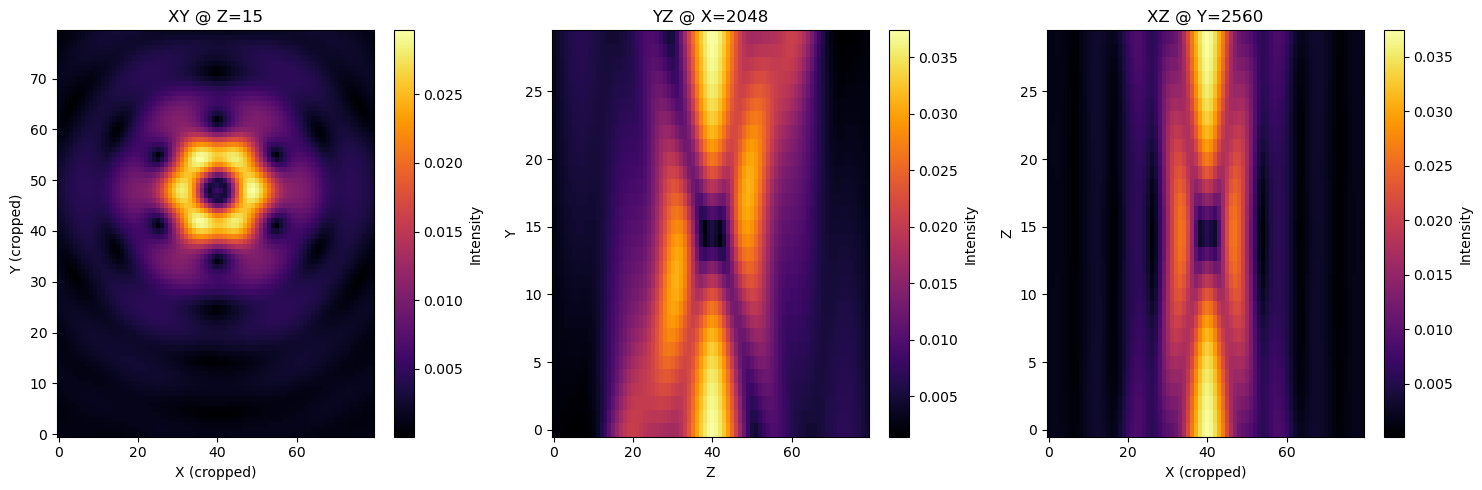

In [45]:
targ = m3d.build_target_from_phase(pbb_2n_bb_superposed)
plot_cropped_sections(m3d.A_t, m3d.pad_factor)

**Phase**

Choose between the simple $6\theta$ phase or the bottle‑beam phase via one draw $\mathrm{rand}_1$:

$$
\phi(r,\theta) =
\begin{cases}
6\theta,                           & \mathrm{if}\;\mathrm{rand}_1 < 0.5,\\[6pt]
\phi_{\rm bottle}(r,\theta),       & \text{otherwise}.
\end{cases}
$$

---

**Far‑field Amplitude**

Superpose the Bessel term with the bottle‑beam amplitude:

$$
E_{\rm ff}(r,\theta)
= \bigl[J_{7}(r)\,\exp\!\bigl(i\,n\theta\bigr) + E_{\rm bottle}(r)\bigr]
\;\ast\;
E_{\rm tweezer}(r,\theta)
$$




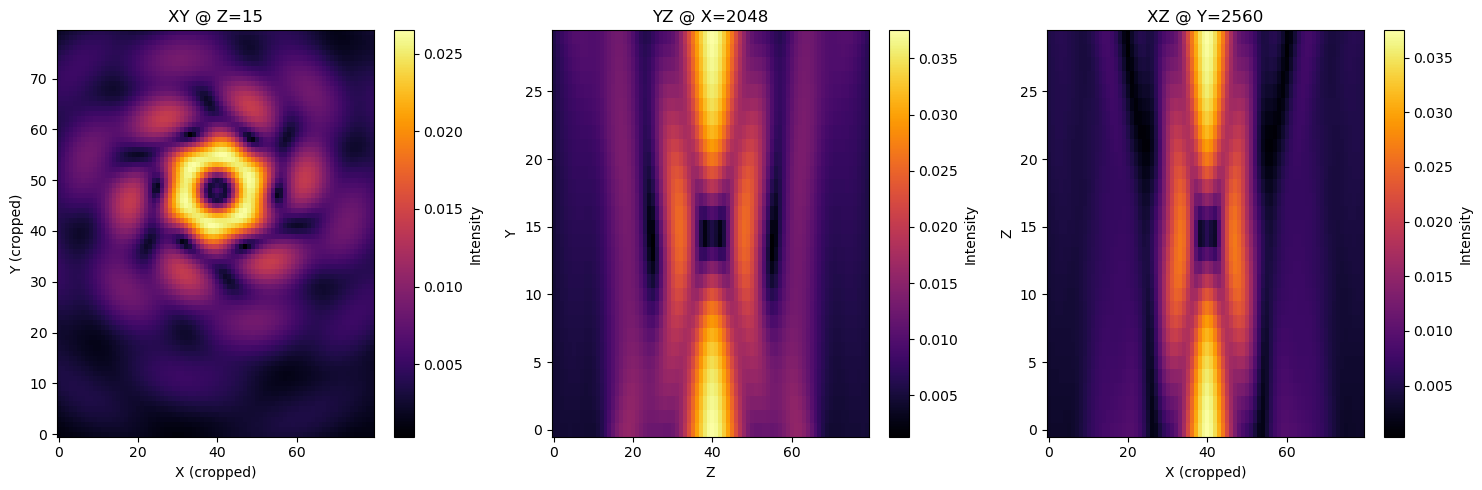

In [47]:
targ = m3d.build_target_from_phase(pbb_n_bb_superposed)
plot_cropped_sections(m3d.A_t, pad_factor=m3d.pad_factor)

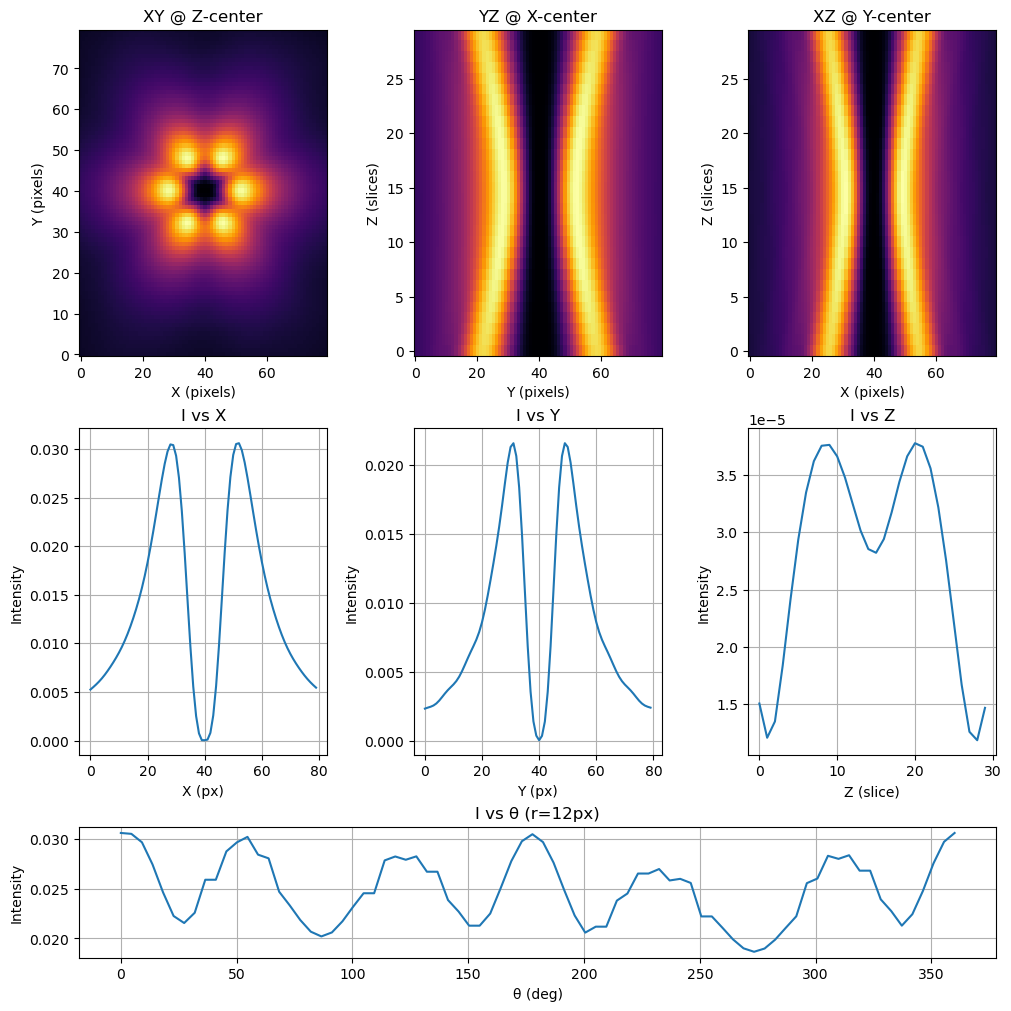

In [91]:
# targ = m3d.build_target_from_phase(pbb_2n_superposed)
plot_cropped_sections(targ, pad_factor=m3d.pad_factor, theta_samples=80)

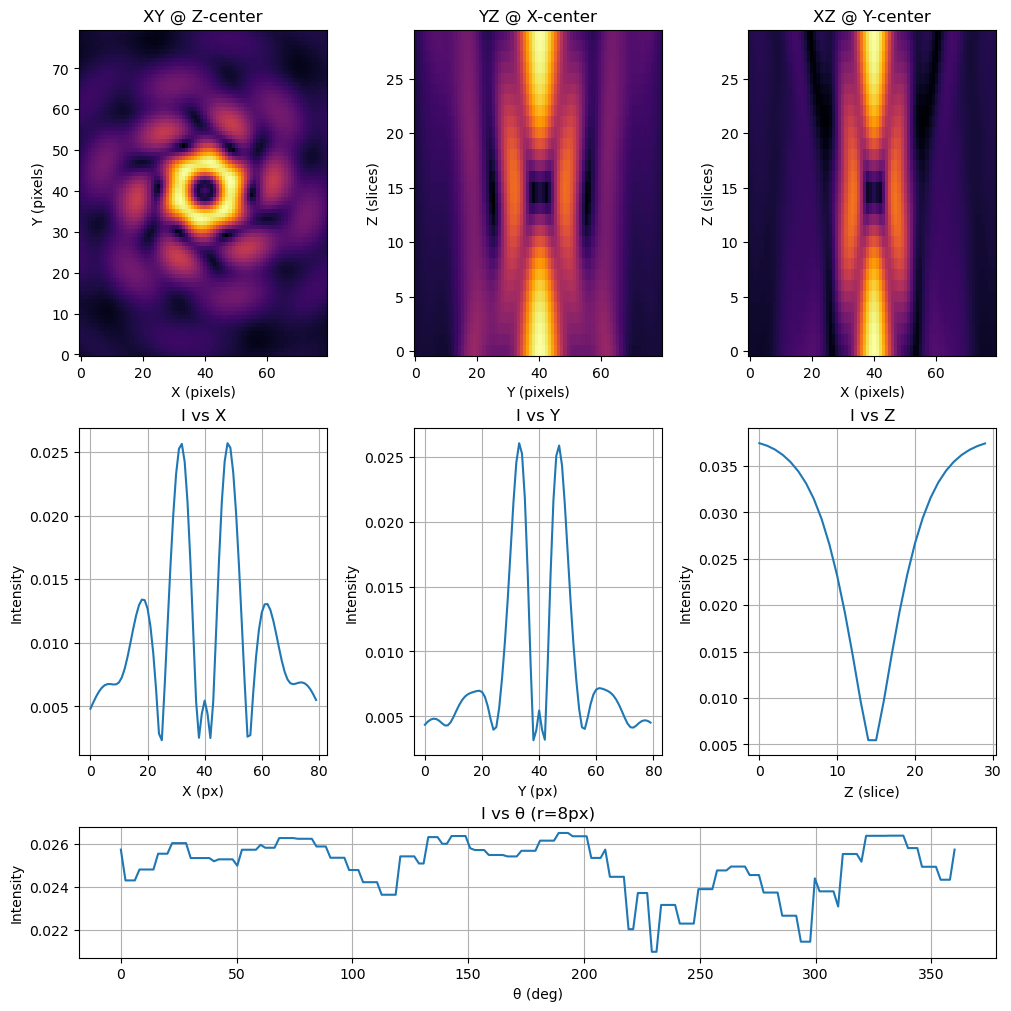

In [90]:
# targ_2n_superposed = m3d.build_target_from_phase(pbb_n_bb_superposed)
plot_cropped_sections(targ_2n_superposed, pad_factor=m3d.pad_factor)

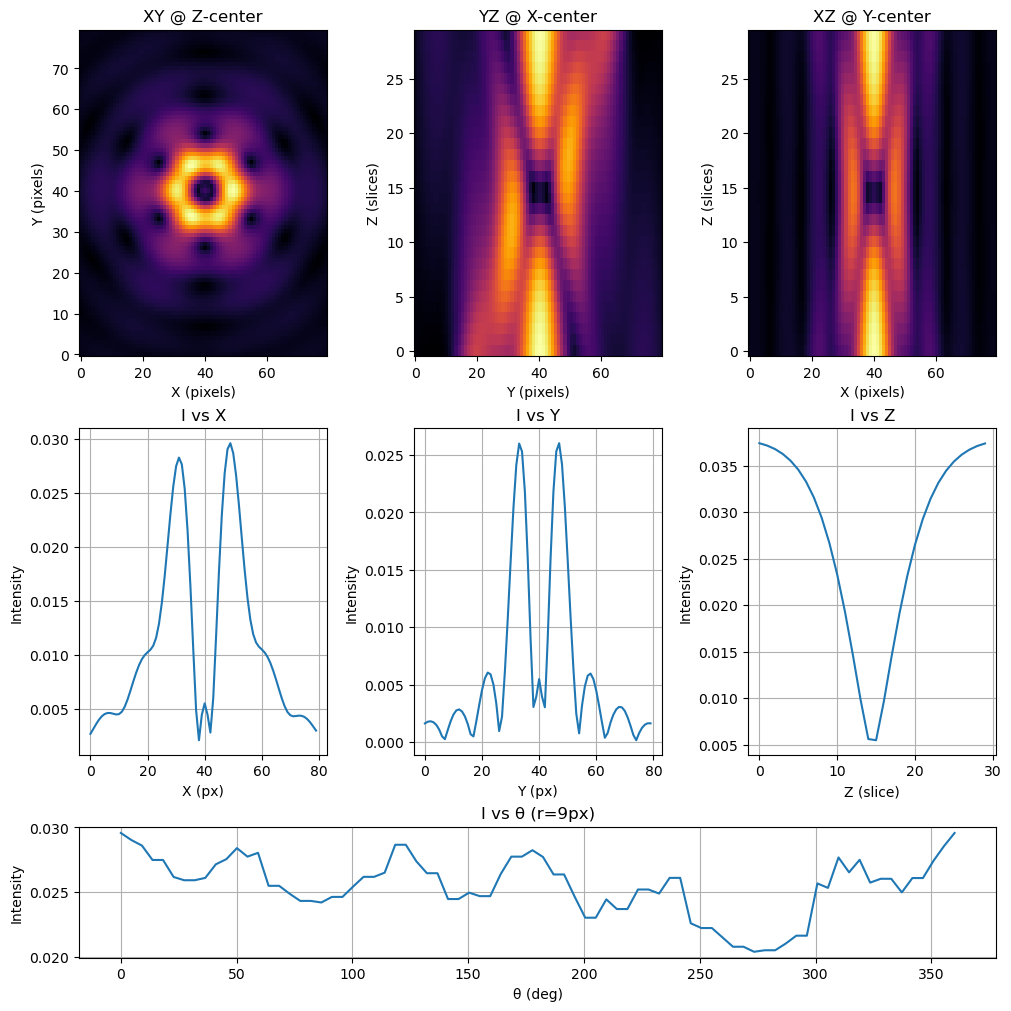

In [89]:
# targ_2n_bb_superposed = m3d.build_target_from_phase(pbb_2n_bb_superposed)
plot_cropped_sections(targ_2n_bb_superposed, pad_factor=m3d.pad_factor, theta_samples=80)

In [88]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.gridspec import GridSpec

def plot_cropped_sections(A_t, pad_factor, r_px=None, theta_samples=180):
    """
    Plots:
      Row 1: 3 image sections (XY @ Z-center, YZ @ X-center, XZ @ Y-center)
      Row 2: 3 line plots (I vs X, I vs Y, I vs Z)
      Row 3: Angular profile (I vs θ) sampled theta_samples times.
    """
    # Convert torch to numpy if needed
    if hasattr(A_t, 'cpu'):
        A_t = A_t.cpu().numpy()
    
    nz, ny, nx = A_t.shape
    z_center = nz // 2
    x_idx = 512 * pad_factor
    y_idx = 640 * pad_factor

    # Crops
    xy = A_t[z_center,
             502 * pad_factor:522 * pad_factor,
             630 * pad_factor:650 * pad_factor]
    yz = A_t[:, x_idx,
            630 * pad_factor:650 * pad_factor]
    xz = A_t[:, 
             502 * pad_factor:522 * pad_factor,
             y_idx]

    # Line cuts
    center_row = xy.shape[0] // 2
    center_col = xy.shape[1] // 2
    I_vs_x = xy[center_row, :]
    I_vs_y = xy[:, center_col]
    I_vs_z = A_t[:, x_idx, y_idx]

    # Auto r_px if not provided
    if r_px is None:
        peak_idx    = np.argmax(I_vs_x)
        crop_center = I_vs_x.size // 2
        r_px        = abs(peak_idx - crop_center)

    # Angular sampling
    theta   = np.linspace(0, 2*np.pi, theta_samples)
    xs_loc = np.clip((center_col + r_px * np.cos(theta)).astype(int), 0, xy.shape[1]-1)
    ys_loc = np.clip((center_row + r_px * np.sin(theta)).astype(int), 0, xy.shape[0]-1)
    I_theta = xy[ys_loc, xs_loc]

    # Create figure
    fig = plt.figure(figsize=(10, 10), constrained_layout=True)
    gs  = GridSpec(3, 3, figure=fig,
                   height_ratios=[1, 1, 0.4],
                   width_ratios =[1, 1, 1])

    # Row 1: heatmaps
    titles = ['XY @ Z-center', 'YZ @ X-center', 'XZ @ Y-center']
    for i, data in enumerate([xy, yz, xz]):
        ax = fig.add_subplot(gs[0, i])
        ax.imshow(data, origin='lower', cmap='inferno', aspect='auto')
        if i == 0:
            ax.set_xlabel('X (pixels)')
            ax.set_ylabel('Y (pixels)')
        elif i == 1:
            ax.set_xlabel('Y (pixels)')
            ax.set_ylabel('Z (slices)')
        else:
            ax.set_xlabel('X (pixels)')
            ax.set_ylabel('Z (slices)')
        ax.set_title(titles[i])

    # Row 2: line plots
    for i, (ydata, xlabel, title) in enumerate([
        (I_vs_x, 'X (px)', 'I vs X'),
        (I_vs_y, 'Y (px)', 'I vs Y'),
        (I_vs_z, 'Z (slice)', 'I vs Z'),
    ]):
        ax = fig.add_subplot(gs[1, i])
        ax.plot(ydata)
        ax.set_xlabel(xlabel)
        ax.set_ylabel('Intensity')
        ax.set_title(title)
        ax.grid(True)

    # Row 3: angular profile
    ax = fig.add_subplot(gs[2, :])
    ax.plot(np.degrees(theta), I_theta)
    ax.set_xlabel('θ (deg)')
    ax.set_ylabel('Intensity')
    ax.set_title(f'I vs θ (r={r_px}px)')
    ax.grid(True)

    plt.show()


# Bottle Beam Aberration

In [33]:
from src.plots import fg
def bottle_beam_phase(sx = 0,sy = 0):
    ro = 210
    return np.array([[np.pi if ((i-512 + sx)**2 + (j-640 + sy)**2) <= ro**2 else 0 for j in range(1280)] for i in range(1024)])

def build_input(H = 1024, W = 1280, width = 2.53538014e+02,sx = 0,sy = 0):
    """ Build an input tensor for the SLM."""
    y = torch.arange(H)
    x = torch.arange(W)
    yy, xx = torch.meshgrid(y, x, indexing='ij')
    return fg((xx, yy), 4.27754945e-01, width, (W / 2) + sx, (H / 2) + sy, 0)



pad_factor = 4
A_input = build_input(sx = 0,sy = 0)
A_target = build_pbb_target(pad_factor=pad_factor,n=0)

# J6_phase = torch.tensor(bottle_beam_phase())

m = SLMphaseRetrievalCG(A_in = A_input,A_t = A_target,pad_factor=pad_factor)



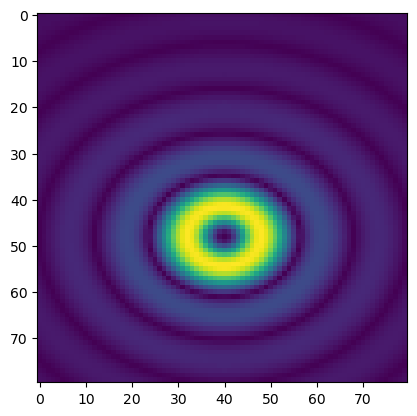

In [34]:
bb_p = torch.tensor(bottle_beam_phase())
plt.imshow(m.forward_propagate(m.pad(tensor=A_input)*m.pad(tensor=torch.exp(1j*bb_p))).abs()[500*pad_factor:520*pad_factor,630*pad_factor:650*pad_factor])

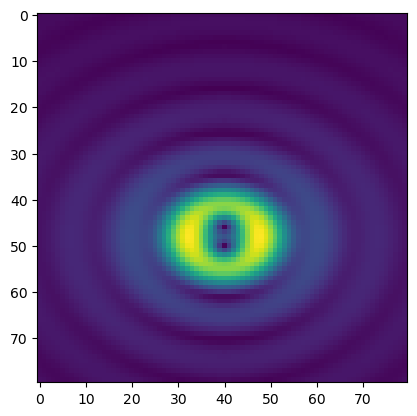

In [31]:
bb_p = torch.tensor(bottle_beam_phase())
plt.imshow(m.forward_propagate(m.pad(tensor=A_input)*m.pad(tensor=torch.exp(1j*bb_p))).abs()[500*pad_factor:520*pad_factor,630*pad_factor:650*pad_factor])

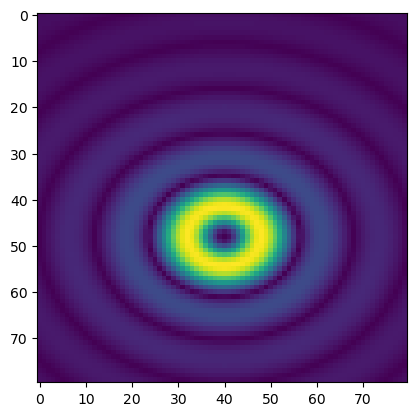

In [32]:
bb_p = torch.tensor(bottle_beam_phase(sx = 0,sy = -100))
plt.imshow(m.forward_propagate(m.pad(tensor=A_input)*m.pad(tensor=torch.exp(1j*bb_p))).abs()[500*pad_factor:520*pad_factor,630*pad_factor:650*pad_factor])